# Saved AO sweep replay
Choose the single-bead SNR sweep or the multiple-bead sweep. Both replay saved intermediate optimizer estimates and three correction events with fixed plotting layouts. Acquisition steps stay hidden.


In [1]:
from pathlib import Path
import sys
import numpy as np
from IPython.display import display
ROOT = Path.cwd()
while not (ROOT / "utils").is_dir():
    if ROOT == ROOT.parent:
        raise RuntimeError("Run inside the repository")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from systematic_testing.ao_animation.viewer import show_replay


/opt/miniconda3/envs/phase_diversity_env/lib/python3.11/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")



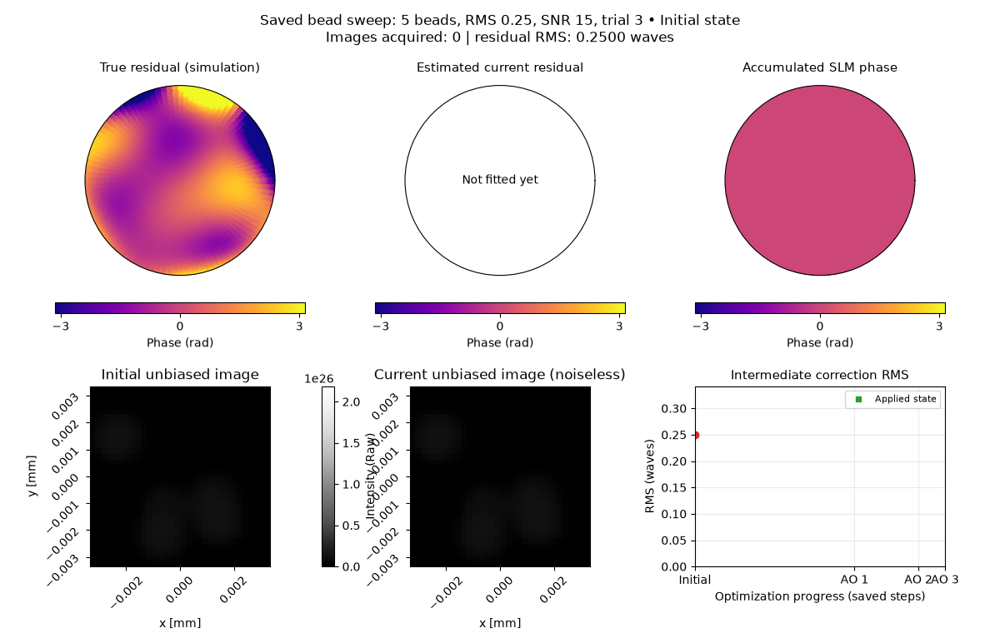
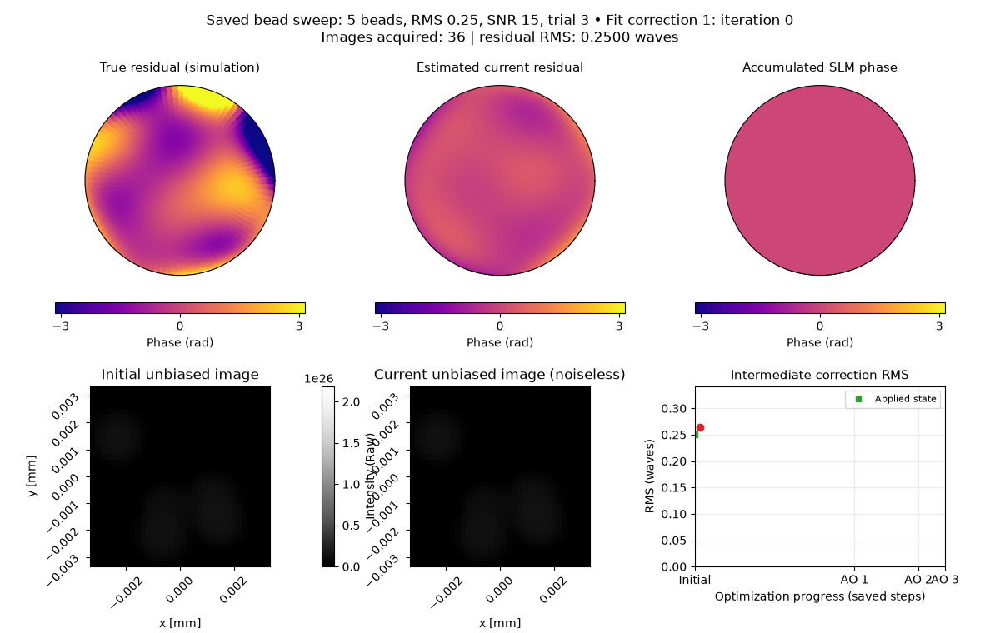
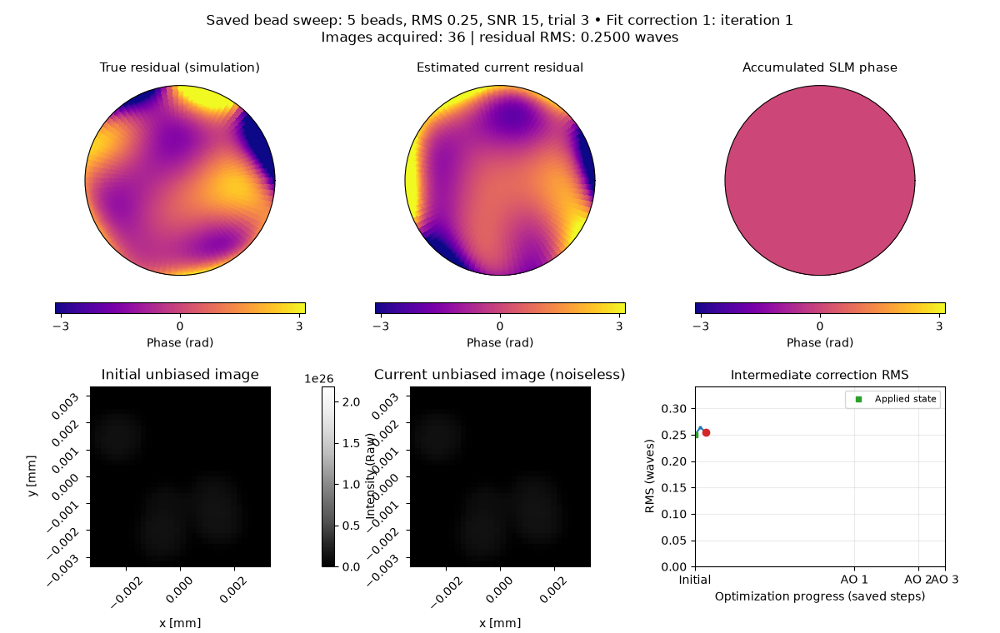
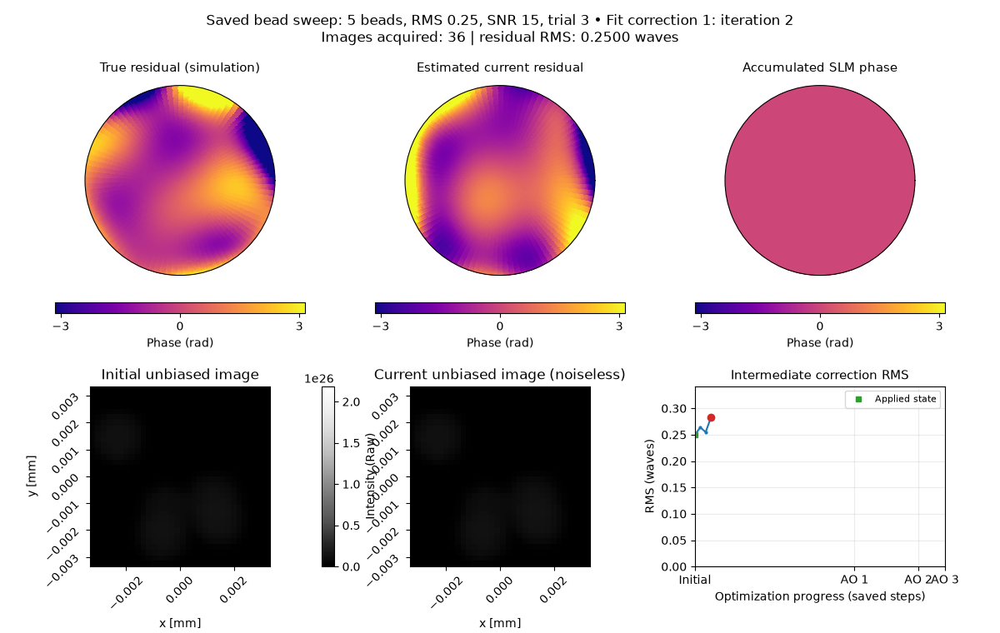
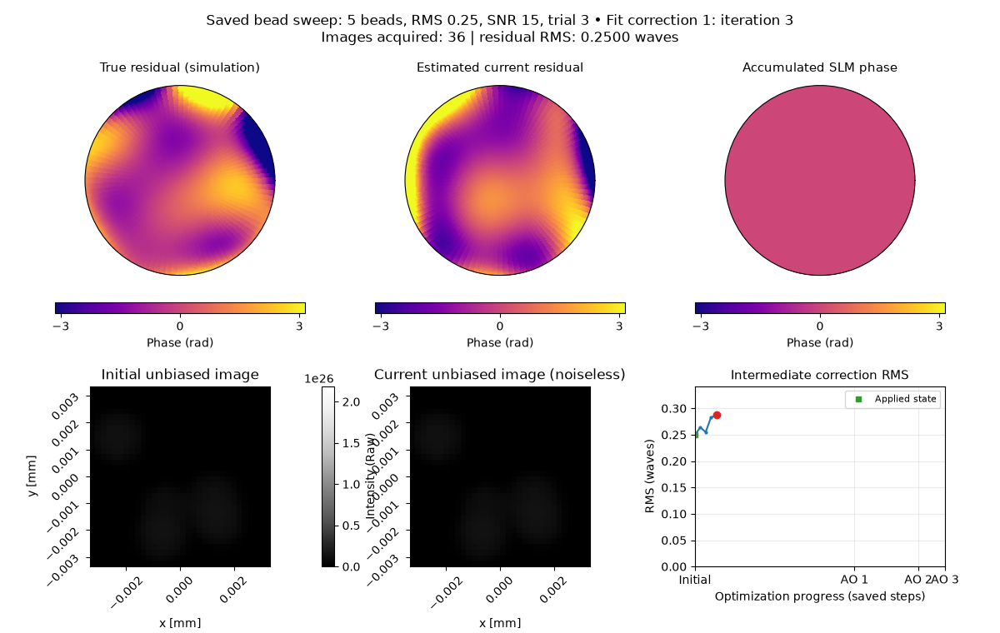
...
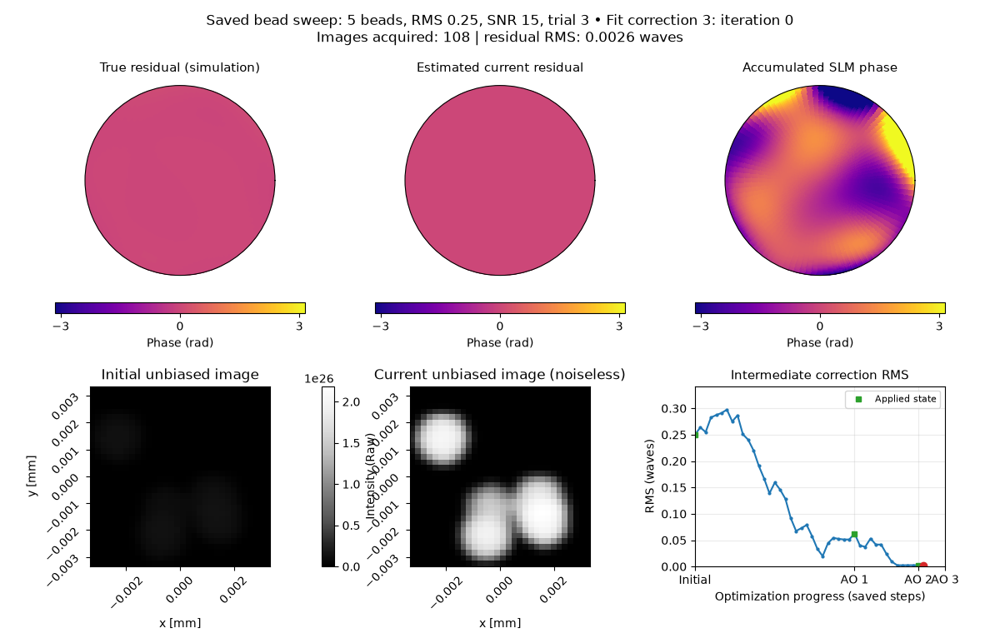
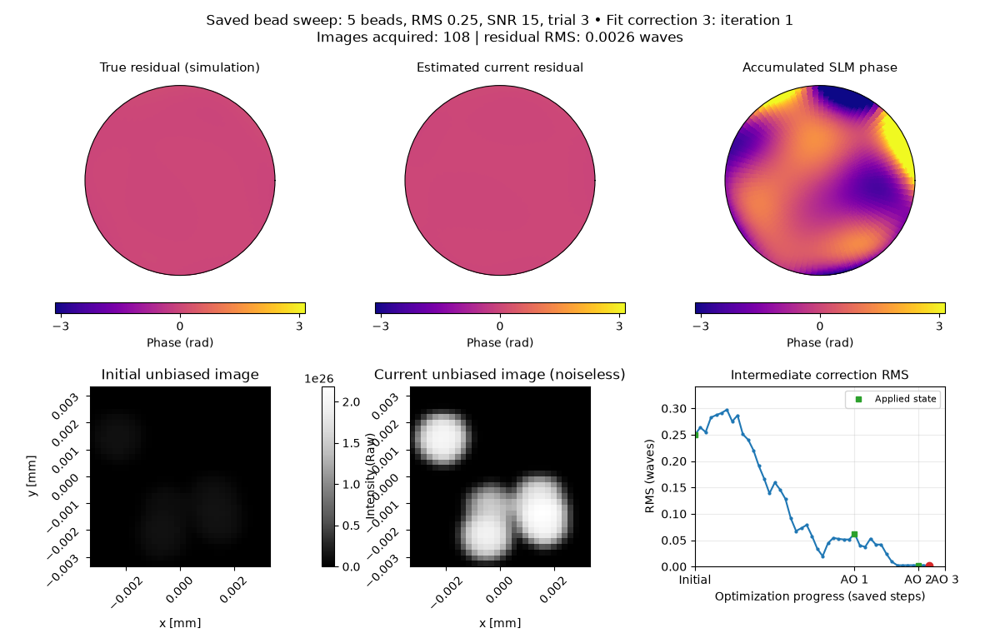
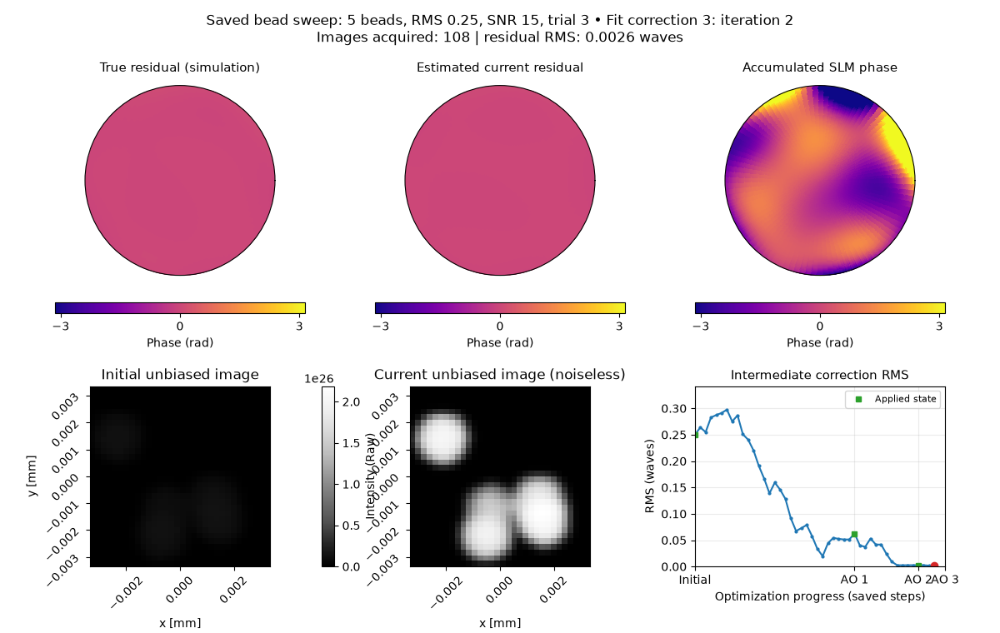
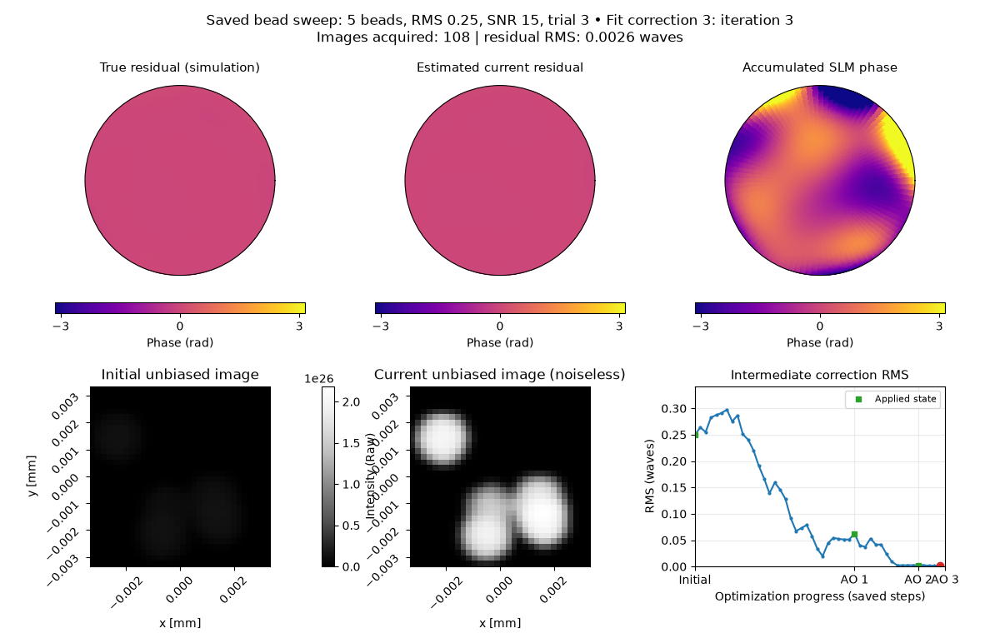
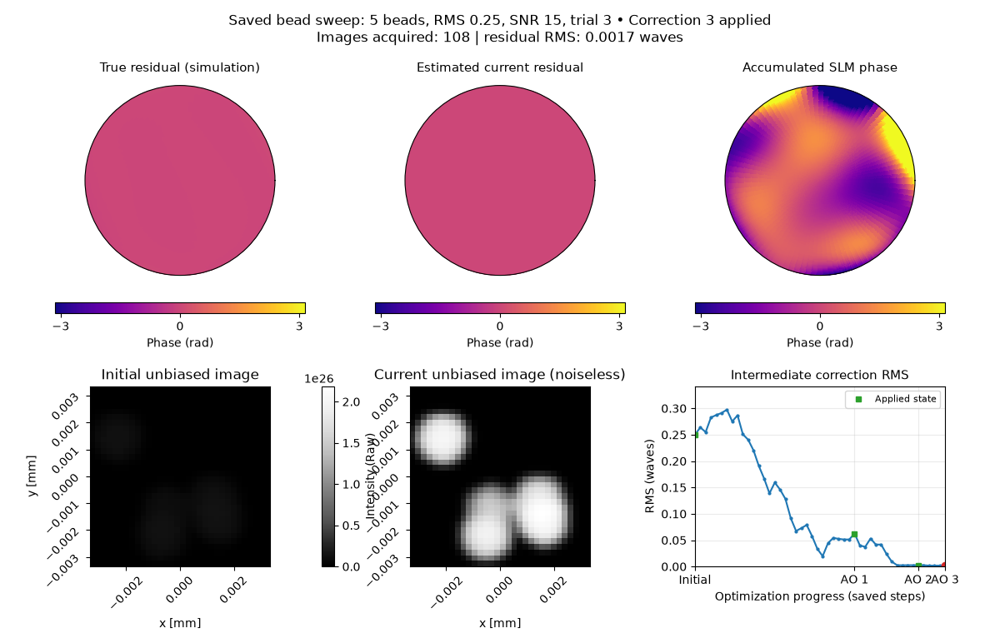

Standalone viewer: /Users/maxwatzky/Documents/GitHub/fall_2026_lab/systematic_testing/ao_animation/beads_case_replay.html


In [5]:
from systematic_testing.ao_animation.snr_replay import load_snr_case, load_bead_case
SWEEP = "beads"  # "beads" or "snr"
RMS_INDEX = 4  # .05,.10,.15,.20,.25,.30
TRIAL = 2     # 0,1,2
BEAD_COUNT = 5  # 1–5, for the bead sweep (fixed calibration SNR 15)
SNR_INDEX = 3   # 5,10,15,20,25,50,100; for the SNR sweep
if SWEEP == "beads":
    frames, points, title = load_bead_case(rms_index=RMS_INDEX, bead_count=BEAD_COUNT, trial=TRIAL)
elif SWEEP == "snr":
    frames, points, title = load_snr_case(rms_index=RMS_INDEX, snr_index=SNR_INDEX, trial=TRIAL)
else:
    raise ValueError('SWEEP must be "beads" or "snr"')
output = ROOT / 'systematic_testing' / 'ao_animation' / f'{SWEEP}_case_replay.html'
display(show_replay(frames, points, title=title, output_path=output))
print(f'Standalone viewer: {output}')


The phase panels use `plotting.zernike_plot`; image panels use `plotting.plot_many_intensity`. Intermediate estimates change during fitting while the actual SLM and physical residual stay fixed. After application, the estimate is transformed into the new SLM reference frame.
